# Разведочный анализ данных (EDA): датасет Yambda-50M
## Проект: рекомендательная система в домене музыкальных треков (ML-трек)

**Датасет:** [yandex/yambda](https://huggingface.co/datasets/yandex/yambda) — Yandex Music Big Dataset

Для изучения возьмем маленький вариант - **Yambda-50M**

Структура данных :
- `listens.parquet` — `uid, item_id, timestamp, is_organic, played_ratio_pct, track_length_seconds`
- `likes.parquet`, `dislikes.parquet`, `unlikes.parquet`, `undislikes.parquet` — `uid, item_id, timestamp, is_organic`
- `multi_event.parquet` — все события одной таблицей + `event_type`
- `embeddings.parquet` — аудио-эмбеддинги треков (`embed`, `normalized_embed`)
- `album_item_mapping.parquet`, `artist_item_mapping.parquet` — связи трек→альбом/артист

Особенности данных:
- `timestamp` — относительное время в секундах, забиннированное с шагом 5 сек (абсолютные даты скрыты);
- `is_organic` = 1 — «органическое» действие (пользователь сам выбрал трек), 0 — из алгоритмической рекомендации;
- `played_ratio_pct > 100` — валидно: пользователь перематывал/слушал трек повторно;
- трек считается прослушанным, если воспроизведено > 50% длительности.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.parquet as pq
from huggingface_hub import snapshot_download

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

BASE = snapshot_download('yandex/yambda', repo_type='dataset',
                         allow_patterns=['flat/50m/*',
                                         'album_item_mapping.parquet',
                                         'artist_item_mapping.parquet',
                                         'embeddings.parquet'])
print('Данные:', BASE)

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Данные: /Users/n.volianskii/.cache/huggingface/hub/datasets--yandex--yambda/snapshots/dd6f3a19eef5866e346c3270e098baa641a44948


## 1. Загрузка данных

In [20]:
listens = pd.read_parquet(f'{BASE}/flat/50m/listens.parquet')
likes = pd.read_parquet(f'{BASE}/flat/50m/likes.parquet')
dislikes = pd.read_parquet(f'{BASE}/flat/50m/dislikes.parquet')
unlikes = pd.read_parquet(f'{BASE}/flat/50m/unlikes.parquet')
undislikes = pd.read_parquet(f'{BASE}/flat/50m/undislikes.parquet')

shapes = pd.DataFrame(
    {'rows': [len(listens), len(likes), len(dislikes), len(unlikes), len(undislikes)],
     'users': [d.uid.nunique() for d in [listens, likes, dislikes, unlikes, undislikes]],
     'items': [d.item_id.nunique() for d in [listens, likes, dislikes, unlikes, undislikes]]},
    index=['listens', 'likes', 'dislikes', 'unlikes', 'undislikes'])
shapes

,rows,users,items
listens,46467212,9238,877168
likes,881456,8283,181304
dislikes,107776,5951,53413
unlikes,312972,6406,117953
undislikes,21033,2911,15399


In [21]:
listens.head()

,uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds
0,100,39420,8326270,0,100,170
1,100,39420,1441281,0,100,105
2,100,39625,286361,0,100,185
3,100,40110,732449,0,100,240
4,100,40360,3397170,0,46,130


In [22]:
listens.dtypes

uid                     uint32
timestamp               uint32
item_id                 uint32
is_organic               uint8
played_ratio_pct        uint16
track_length_seconds    uint32
dtype: object

Наблюдение: Все поля — беззнаковые целые (`uint8/16/32`), то есть NaN и отрицательные значения в flat-файлах невозможны на уровне типа данных.

## 2. Основные статистики (`describe`)

In [23]:
listens.describe(include='all')

,uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds
count,"46,467,212.00","46,467,212.00","46,467,212.00","46,467,212.00","46,467,212.00","46,467,212.00"
mean,"498,499.04","14,448,380.92","4,713,863.83",0.52,64.76,207.41
std,"287,300.10","7,463,941.69","2,701,184.22",0.50,44.09,89.21
min,100.00,0.00,22.00,0.00,0.00,5.00
25%,"249,400.00","8,207,915.00","2,396,488.00",0.00,7.00,165.00
50%,"494,200.00","15,089,450.00","4,715,228.00",1.00,100.00,200.00
75%,"744,600.00","21,057,150.00","7,050,175.00",1.00,100.00,230.00
max,"1,000,000.00","26,000,000.00","9,390,623.00",1.00,159.00,"2,495.00"


In [24]:
likes.describe(include='all')

,uid,timestamp,item_id,is_organic
count,"881,456.00","881,456.00","881,456.00","881,456.00"
mean,"504,442.95","14,495,398.34","4,707,555.90",0.57
std,"288,425.77","7,740,868.37","2,704,586.78",0.50
min,100.00,80.00,26.00,0.00
25%,"255,600.00","7,751,601.25","2,381,020.00",0.00
50%,"510,400.00","15,411,015.00","4,714,327.00",1.00
75%,"763,700.00","21,450,781.25","7,041,449.00",1.00
max,"1,000,000.00","25,999,970.00","9,390,522.00",1.00


Что видно из статистик:
- `timestamp` $\in$ [0, ~26 млн сек] ≈ 301 день наблюдений.
- `played_ratio_pct`: медиана = 100 (типичное прослушивание — полное), среднее ~64.8 — значит, есть тяжёлый левый хвост скипов. Минимум 0 (мгновенный скип), максимум 159.
- `track_length_seconds`: медиана 200 сек (~3.3 мин) — обычная длина трека; максимум 2495 сек (~42 мин) — скорее всего, какие-нибудь длинные миксы/подкасты.
- `is_organic`: доля органических прослушиваний ~51.7% — почти половина трафика идёт от алгоритмических рекомендаций, что важно учитывать (feedback loop).

## 3. Пропущенные значения

Проверяем пропуски во всех файлах событий и в объединённом `multi_event.parquet`.

In [25]:
na = pd.DataFrame({name: df.isna().sum() for name, df in [('listens', listens), ('likes', likes), ('dislikes', dislikes),
                                                            ('unlikes', unlikes), ('undislikes', undislikes)]}).T
na['total_na'] = na.sum(axis=1)
na['na_share_%'] = (na['total_na'] / pd.Series({'listens': len(listens), 'likes': len(likes),
                                                'dislikes': len(dislikes), 'unlikes': len(unlikes),
                                                'undislikes': len(undislikes)}) * 100).round(4)
na

,is_organic,item_id,played_ratio_pct,timestamp,track_length_seconds,uid,total_na,na_share_%
listens,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
likes,0.00,0.00,NaN,0.00,NaN,0.00,0.00,0.00
dislikes,0.00,0.00,NaN,0.00,NaN,0.00,0.00,0.00
unlikes,0.00,0.00,NaN,0.00,NaN,0.00,0.00,0.00
undislikes,0.00,0.00,NaN,0.00,NaN,0.00,0.00,0.00


Вывод: В раздельных файлах событий пропусков нет — датасет предочищен.

## 4. Ошибочные значения

Проверяем типичные ошибки: отрицательные/невозможные значения, некорректные доли, дубликаты, покрытие сущностей.

In [26]:
checks = {
    'played_ratio_pct < 0': (listens.played_ratio_pct < 0).sum(),
    'track_length_seconds <= 0': (listens.track_length_seconds <= 0).sum(),
    'timestamp < 0': (listens.timestamp < 0).sum(),
    'дубликаты (uid, item_id, timestamp)': listens.duplicated(subset=['uid', 'item_id', 'timestamp']).sum(),
    'полные дубликаты строк': listens.duplicated().sum(),
}
pd.Series(checks).to_frame('count')

,count
played_ratio_pct < 0,0
track_length_seconds <= 0,0
timestamp < 0,0
"дубликаты (uid, item_id, timestamp)",588035
полные дубликаты строк,225625


In [27]:
# Покрытие сущностей: сверяем с карточкой датасета (10 000 пользователей, 934 057 треков)
all_users = set(listens.uid) | set(likes.uid) | set(dislikes.uid) | set(unlikes.uid) | set(undislikes.uid)
all_items = set(listens.item_id) | set(likes.item_id) | set(dislikes.item_id) | set(unlikes.item_id) | set(undislikes.item_id)
print(f'Уникальных пользователей (объединение всех файлов): {len(all_users):,} (ожидалось 10 000)')
print(f'Уникальных треков: {len(all_items):,} (ожидалось 934 057)')
print(f'Пользователей в listens: {listens.uid.nunique():,}; в likes: {likes.uid.nunique():,}; '
f'в dislikes: {dislikes.uid.nunique():,}')
print(f'Пользователей только с likes/dislikes (без прослушиваний): {len(all_users - set(listens.uid))}')

Уникальных пользователей (объединение всех файлов): 10,000 (ожидалось 10 000)
Уникальных треков: 934,057 (ожидалось 934 057)
Пользователей в listens: 9,238; в likes: 8,283; в dislikes: 5,951
Пользователей только с likes/dislikes (без прослушиваний): 762


In [28]:
# unlike должен идти после like (и undislike после dislike)
m_lu = likes.merge(unlikes, on=['uid', 'item_id'], suffixes=('_like', '_unlike'))
print(f'Пар (uid,item) с like и unlike: {len(m_lu):,}; '
      f'unlike позже like: {(m_lu.timestamp_unlike >= m_lu.timestamp_like).mean():.3f}')

m_ld = likes.merge(dislikes, on=['uid', 'item_id'], suffixes=('_like', '_dislike'))
print(f'Пар с like и dislike одновременно: {len(m_ld):,}; '
      f'dislike позже like: {(m_ld.timestamp_dislike >= m_ld.timestamp_like).mean():.3f}')

# unlike/undislike без like/dislike в окне наблюдений
lk_pairs  = set(zip(likes.uid, likes.item_id))
ulk_pairs = set(zip(unlikes.uid, unlikes.item_id))
dl_pairs  = set(zip(dislikes.uid, dislikes.item_id))
udl_pairs = set(zip(undislikes.uid, undislikes.item_id))
print(f'unlike без like в данных: {len(ulk_pairs - lk_pairs):,} из {len(ulk_pairs):,} '
      f'({len(ulk_pairs - lk_pairs)/len(ulk_pairs):.1%})')
print(f'undislike без dislike: {len(udl_pairs - dl_pairs):,} из {len(udl_pairs):,} '
      f'({len(udl_pairs - dl_pairs)/len(udl_pairs):.1%})')

Пар (uid,item) с like и unlike: 152,101; unlike позже like: 0.785
Пар с like и dislike одновременно: 14,865; dislike позже like: 0.808
unlike без like в данных: 208,725 из 290,486 (71.9%)
undislike без dislike: 13,393 из 19,145 (70.0%)


Выводы:
1. Невозможных значений нет: Отрицательных долей/длин/времени не обнаружено (и типы `uint` их исключают).
2. Дубликаты по (uid, item_id, timestamp) — 588 035 (1.3%): это, скорее всего, происходит из-за маппинга в 5-секундные интервалы — пользователь мог начать один и тот же трек дважды внутри одного 5-секундного интервала. При построения матрицы интеракций они не мешают.
3. 78.5% пар like→unlike идут в правильном порядке; ~21.5% обратных событий можно объяснить тем, что, скорее всего, like произошёл до начала окна наблюдений. Аналогично 72% unlike без видимого like.
4. 11–15 тыс. пар с одновременным like и dislike — пользователи меняют мнение о треке со временем; для модели полезен именно последний сигнал.
5. Покрытие сущностей сходится с карточкой: 10 000 пользователей в объединении файлов. 762 пользователя без прослушиваний в окне.

## 5. Выбросы

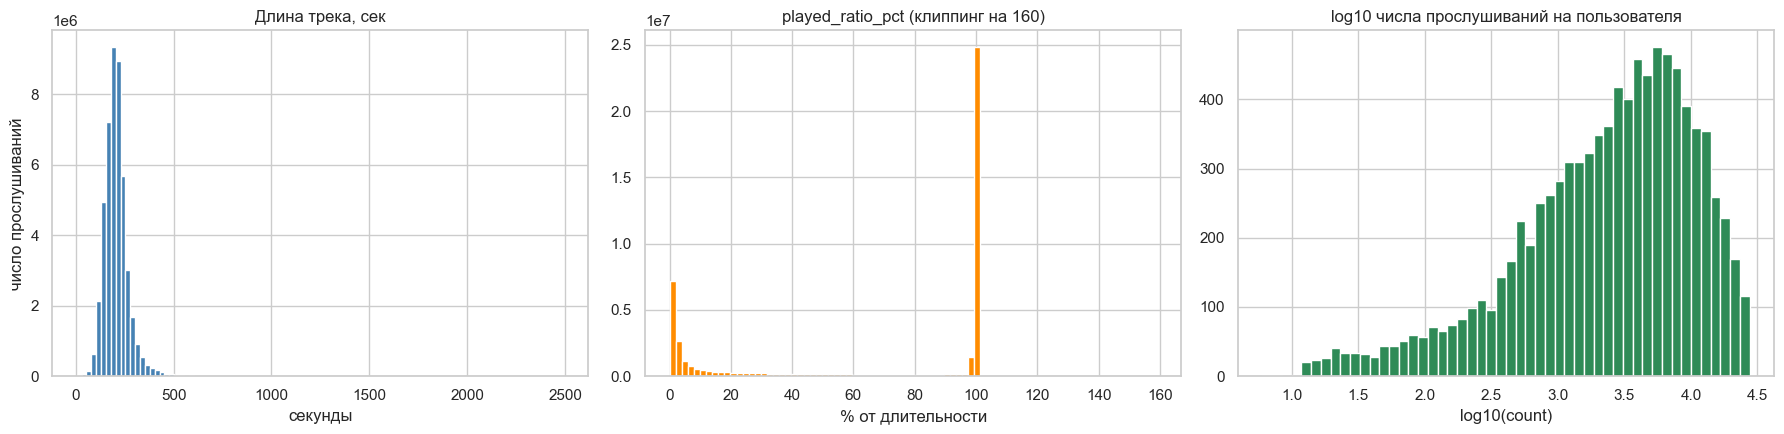

Треки длиннее 30 минут: 31564 (0.0679% прослушиваний)


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(listens.track_length_seconds, bins=100, color='steelblue')
axes[0].set_title('Длина трека, сек')
axes[0].set_xlabel('секунды'); axes[0].set_ylabel('число прослушиваний')

axes[1].hist(listens.played_ratio_pct.clip(0, 160), bins=80, color='darkorange')
axes[1].set_title('played_ratio_pct (клиппинг на 160)')
axes[1].set_xlabel('% от длительности')

user_cnt = listens.groupby('uid').size()
axes[2].hist(np.log10(user_cnt), bins=50, color='seagreen')
axes[2].set_title('log10 числа прослушиваний на пользователя')
axes[2].set_xlabel('log10(count)')
plt.tight_layout(); plt.show()

print('Треки длиннее 30 минут:', (listens.track_length_seconds > 1800).sum(),
      f'({(listens.track_length_seconds > 1800).mean():.4%} прослушиваний)')

Выводы:
- Длина трека: тяжёлый правый хвост — записи до 42 минут. Длину стоит использовать как признак/нормировщик (через `played_ratio_pct` она уже учтена).
- played_ratio_pct: значения >100 (~0.5%) — валидные переслушивания. Мгновенные скипы (ratio=0) — 7.4% событий — не выбросы.
- Активность пользователей: от 6 до 27 617 прослушиваний. Экстремально активные пользователи правдоподобны для стриминга (фоновое прослушивание, общие аккаунты); удалять не будем, но при обучении моделей имеет смысл клиппить веса слишком активных пользователей.

## 6. Распределение признаков по отдельности

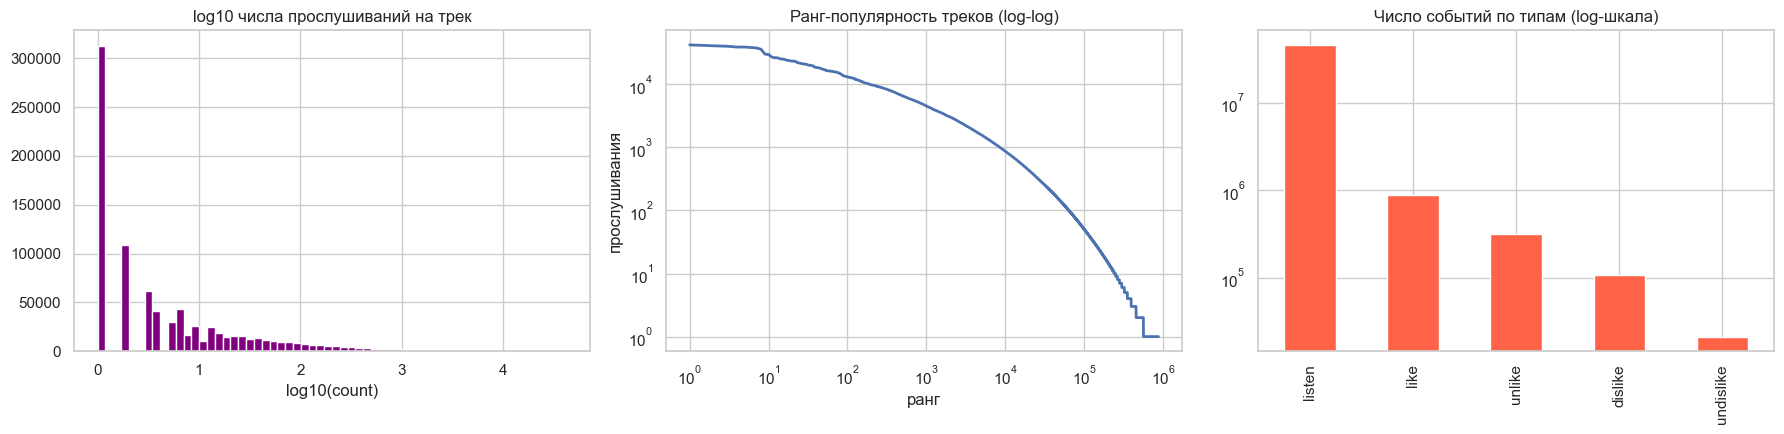

Топ-1% треков собирают 49.2% всех прослушиваний
Медиана прослушиваний трека: 3; треков с единственным прослушиванием: 35.7%


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

item_cnt = listens.groupby('item_id').size()
axes[0].hist(np.log10(item_cnt), bins=60, color='purple')
axes[0].set_title('log10 числа прослушиваний на трек')
axes[0].set_xlabel('log10(count)')

top = item_cnt.nlargest(int(len(item_cnt)*0.01)).sum()
ranks = np.arange(1, len(item_cnt)+1)
axes[1].loglog(ranks, np.sort(item_cnt.values)[::-1], lw=2)
axes[1].set_title('Ранг-популярность треков (log-log)')
axes[1].set_xlabel('ранг'); axes[1].set_ylabel('прослушивания')

events = pd.Series({'listen': len(listens), 'like': len(likes), 'unlike': len(unlikes),
                    'dislike': len(dislikes), 'undislike': len(undislikes)})
events.plot.bar(ax=axes[2], logy=True, color='tomato')
axes[2].set_title('Число событий по типам (log-шкала)')
plt.tight_layout(); plt.show()

print(f'Топ-1% треков собирают {top/item_cnt.sum():.1%} всех прослушиваний')
print(f'Медиана прослушиваний трека: {item_cnt.median():.0f}; '
      f'треков с единственным прослушиванием: {(item_cnt==1).mean():.1%}')

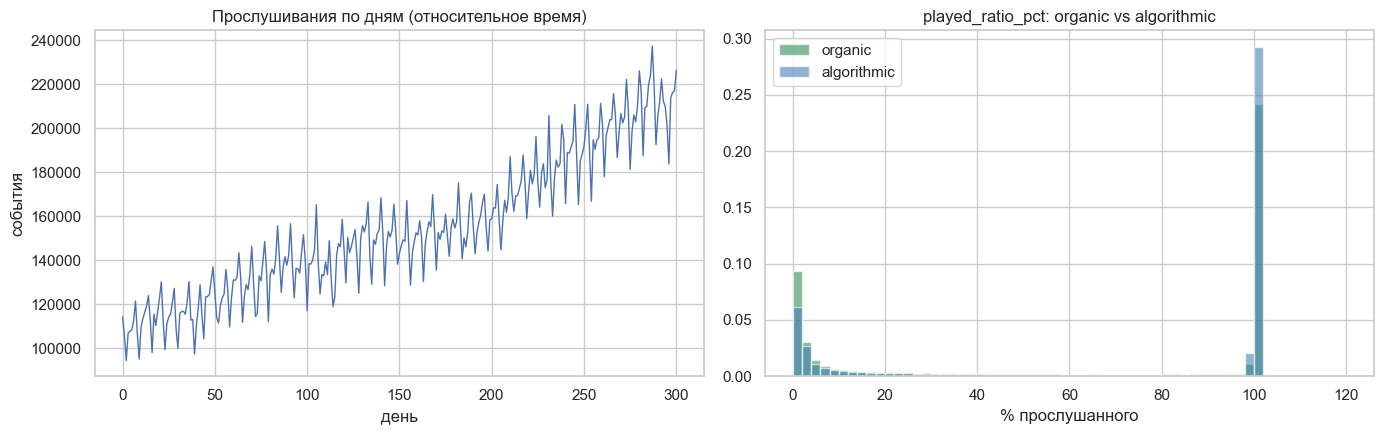

            mean  median
is_organic              
0          69.61  100.00
1          60.22   99.00


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

days = (listens.timestamp / 86400).astype(int).value_counts().sort_index()
axes[0].plot(days.index, days.values, lw=1)
axes[0].set_title('Прослушивания по дням (относительное время)')
axes[0].set_xlabel('день'); axes[0].set_ylabel('события')

sample = listens.sample(300_000, random_state=42)
for org, label, color in [(1, 'organic', 'seagreen'), (0, 'algorithmic', 'steelblue')]:
    axes[1].hist(sample[sample.is_organic == org].played_ratio_pct.clip(0, 120),
                 bins=60, alpha=0.6, density=True, label=label, color=color)
axes[1].set_title('played_ratio_pct: organic vs algorithmic')
axes[1].set_xlabel('% прослушанного'); axes[1].legend()
plt.tight_layout(); plt.show()

print(listens.groupby('is_organic').played_ratio_pct.agg(['mean', 'median']))

Выводы:
- Длинный хвост популярности: топ-1% треков (≈8.8 тыс.) дают ~49% всех прослушиваний; у 35.7% треков — единственное прослушивание. Это проблема холодных айтемов: популярностный бейзлайн будет хорошо себя показывать, но персонализация должна вытаскивать хвост.
- organic vs algorithmic: у алгоритмических прослушиваний средняя доля прослушивания выше (~69.6% vs ~60.2%). Это отражает feedback loop: рекоммендер уже подбирает "безопасные" треки. При обучении на таких данных модель рискует унаследовать смещение старой системы (exposure bias) — стоит либо обучаться преимущественно на organic-сигналах, либо учитывать `is_organic` как признак.

## 7. Целевая переменная

Задача — рекомендация треков. По официальному протоколу датасета **положительное взаимодействие = прослушивание > 50% длительности**. Также есть явные сигналы: like (сильный позитив), dislike (негатив).

In [32]:
listens['listened'] = (listens.played_ratio_pct > 50).astype(np.uint8)
print(f'Доля прослушанных (>50%): {listens.listened.mean():.3f}')
print(f'Доля мгновенных скипов (ratio=0): {(listens.played_ratio_pct == 0).mean():.3f}')

print(f'\nЛайков: {len(likes):,}; дизлайков: {len(dislikes):,} → лайков в {len(likes)/len(dislikes):.1f} раза больше')

lk = likes[['uid', 'item_id']].drop_duplicates()
lp = listens[['uid', 'item_id']].drop_duplicates()
mm = lk.merge(lp, on=['uid', 'item_id'], how='left', indicator=True)
print(f'Лайкнутых пар без прослушивания в окне: {(mm._merge == "left_only").mean():.1%} '
      f'(лайк поставлен на внешней поверхности или прослушивание было до окна наблюдений)')

Доля прослушанных (>50%): 0.632
Доля мгновенных скипов (ratio=0): 0.074

Лайков: 881,456; дизлайков: 107,776 → лайков в 8.2 раза больше
Лайкнутых пар без прослушивания в окне: 16.5% (лайк поставлен на внешней поверхности или прослушивание было до окна наблюдений)


## 8. Разреженность матрицы взаимодействий и попарные корреляции

Ключевые характеристики для рекомендательной системы.

In [33]:
n_u, n_i = listens.uid.nunique(), listens.item_id.nunique()
n_pairs = listens[['uid', 'item_id']].drop_duplicates().shape[0]
print(f'Пользователей: {n_u:,}; треков: {n_i:,}')
print(f'Уникальных пар (user, item): {n_pairs:,}')
print(f'Плотность матрицы: {n_pairs/(n_u*n_i)*100:.4f}%  (разреженность {100 - n_pairs/(n_u*n_i)*100:.4f}%)')
print(f'Среднее число уникальных треков на пользователя: {n_pairs/n_u:.0f}')
print(f'Среднее число слушателей у трека: {n_pairs/n_i:.1f}')

Пользователей: 9,238; треков: 877,168
Уникальных пар (user, item): 13,268,889
Плотность матрицы: 0.1637%  (разреженность 99.8363%)
Среднее число уникальных треков на пользователя: 1436
Среднее число слушателей у трека: 15.1


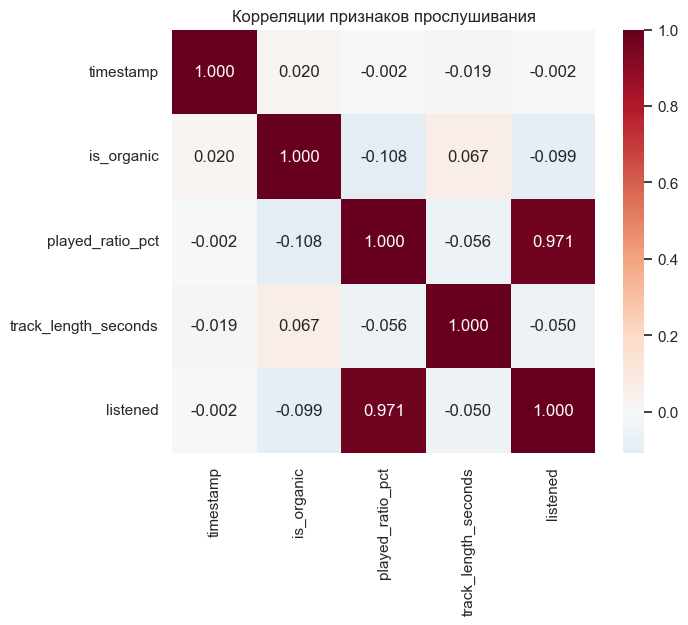

                      corr с listened
played_ratio_pct                 0.97
is_organic                      -0.10
track_length_seconds            -0.05
timestamp                       -0.00


In [34]:
num_cols = ['timestamp', 'is_organic', 'played_ratio_pct', 'track_length_seconds', 'listened']
sample = listens[num_cols].sample(500_000, random_state=42)
corr = sample.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0, square=True, ax=ax)
ax.set_title('Корреляции признаков прослушивания')
plt.show()
print(corr['listened'].drop('listened').sort_values(key=abs, ascending=False).to_frame('corr с listened'))

            не прослушан (<=50%) прослушан (>50%)
algorithmic                31.9%            68.1%
organic                    41.3%            58.7%


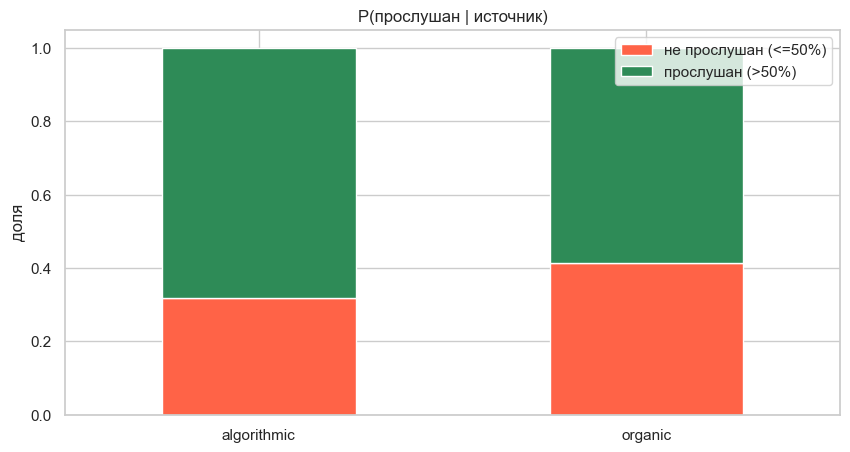

In [35]:
ct = pd.crosstab(listens.is_organic, listens.listened, normalize='index')
ct.columns = ['не прослушан (<=50%)', 'прослушан (>50%)']
ct.index = ['algorithmic', 'organic']
print((ct * 100).round(1).astype(str) + '%')
ct.plot.bar(stacked=True, color=['tomato', 'seagreen'])
plt.title('P(прослушан | источник)'); plt.ylabel('доля'); plt.xticks(rotation=0); plt.show()

Выводы:
- Единственный сильный предсказатель прослушивания — сама доля прослушивания (что логично); из остальных признаков заметна слабая положительная связь `track_length_seconds` с `played_ratio_pct` (длинные треки дослушивают пропорционально чаще — вероятно, их включают осознанно) и слабая отрицательная связь `is_organic` с фактом дослушивания (алгоритмические выдачи дослушиваются чаще органических).
- Корреляции по событиям слабые, значит главный сигнал для рекомендаций лежит не в признаках события, а в структуре взаимодействий (коллаборативная составляющая) и контенте (эмбеддинги). Это подтверждает выбор CF/sequential-подходов как основных.

## 9. Динамика лайков и дизлайков во времени

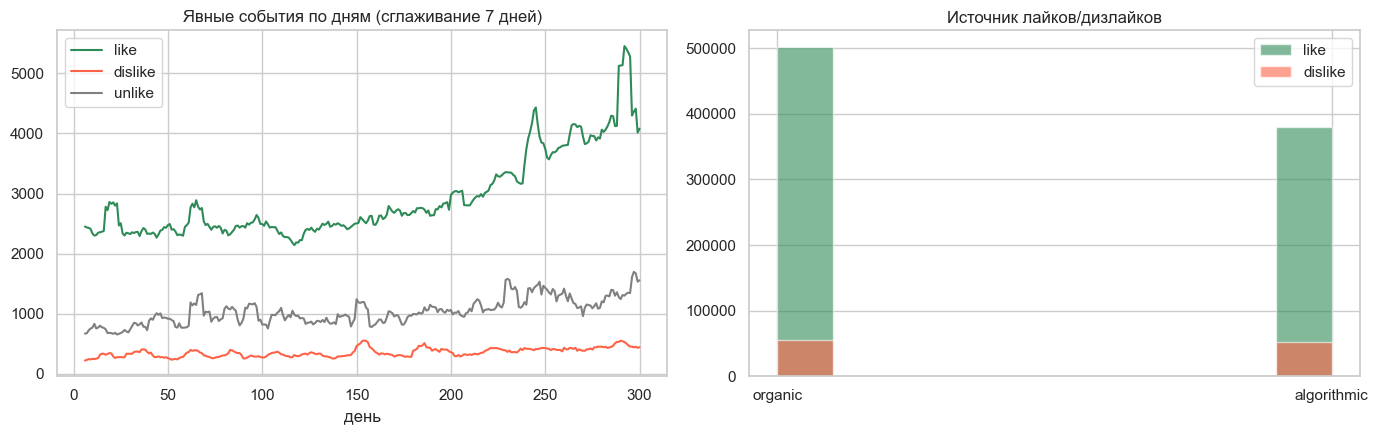

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for df, name, color in [(likes, 'like', 'seagreen'), (dislikes, 'dislike', 'tomato'),
                        (unlikes, 'unlike', 'gray')]:
    d = (df.timestamp / 86400).astype(int).value_counts().sort_index()
    axes[0].plot(d.index, d.rolling(7).mean().values, label=name, color=color)
axes[0].set_title('Явные события по дням (сглаживание 7 дней)')
axes[0].set_xlabel('день'); axes[0].legend()

axes[1].hist(likes.is_organic.replace({0: 'algorithmic', 1: 'organic'}), alpha=0.6, label='like', color='seagreen')
axes[1].hist(dislikes.is_organic.replace({0: 'algorithmic', 1: 'organic'}), alpha=0.6, label='dislike', color='tomato')
axes[1].set_title('Источник лайков/дизлайков'); axes[1].legend()
plt.tight_layout(); plt.show()

## 10. Артисты и альбомы (маппинги)

artist_item_mapping: (9271906, 2), уникальных артистов: 1,293,394
album_item_mapping:  (9651644, 2), уникальных альбомов: 3,367,691

Покрытие треков 50M артист-маппингом: 99.368%
Покрытие треков 50M альбом-маппингом:  99.524%
Треков с несколькими артистами (фиты): 1,400

Среднее треков на артиста (каталог): 7.2, медиана: 2


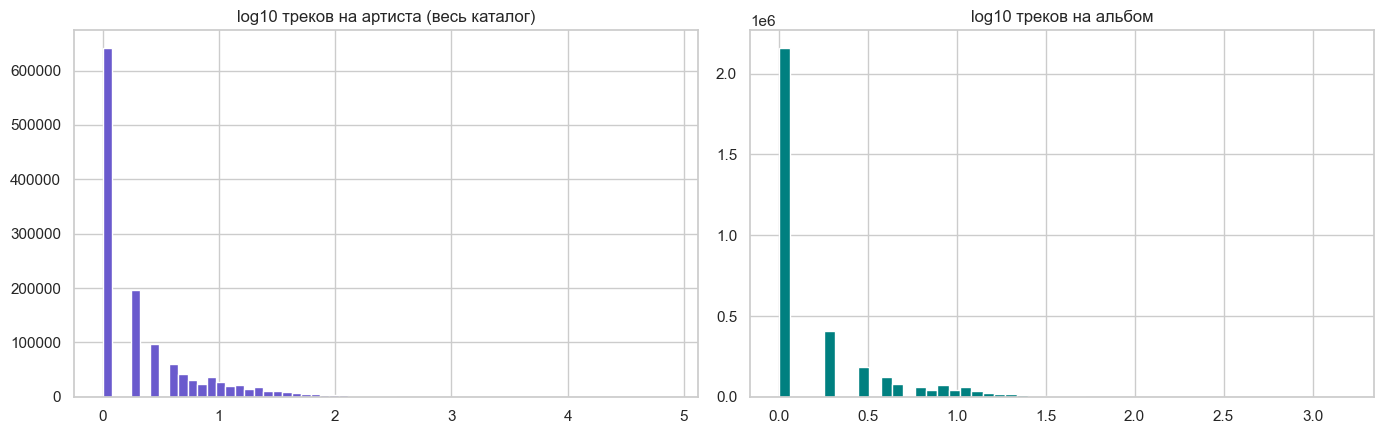

In [39]:
artist_map = pd.read_parquet(f'{BASE}/artist_item_mapping.parquet')
album_map  = pd.read_parquet(f'{BASE}/album_item_mapping.parquet')
print(f'artist_item_mapping: {artist_map.shape}, уникальных артистов: {artist_map.artist_id.nunique():,}')
print(f'album_item_mapping:  {album_map.shape}, уникальных альбомов: {album_map.album_id.nunique():,}')

items_50m = pd.Series(list(set(listens.item_id) | set(likes.item_id) | set(dislikes.item_id)))
print(f'\nПокрытие треков 50M артист-маппингом: {items_50m.isin(artist_map.item_id).mean():.3%}')
print(f'Покрытие треков 50M альбом-маппингом:  {items_50m.isin(album_map.item_id).mean():.3%}')
print(f'Треков с несколькими артистами (фиты): {(artist_map.groupby("item_id").size() > 1).sum():,}')

item_agg = listens.groupby('item_id').agg(
    n_listens=('uid', 'size'),
    mean_ratio=('played_ratio_pct', 'mean'),
    full_listen_share=('listened', 'mean'))
item_agg['n_likes']    = likes.groupby('item_id').size()
item_agg['n_dislikes'] = dislikes.groupby('item_id').size()
item_agg[['n_likes', 'n_dislikes']] = item_agg[['n_likes', 'n_dislikes']].fillna(0)
item_agg['like_rate']    = item_agg.n_likes / item_agg.n_listens
item_agg['dislike_rate'] = item_agg.n_dislikes / item_agg.n_listens

tracks_per_artist = artist_map.groupby('artist_id').size()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(np.log10(tracks_per_artist), bins=60, color='slateblue')
axes[0].set_title('log10 треков на артиста (весь каталог)')
pop_items = item_agg.nlargest(50_000, 'n_listens').index
art_pop = artist_map[artist_map.item_id.isin(pop_items)]
print(f'\nСреднее треков на артиста (каталог): {tracks_per_artist.mean():.1f}, '
      f'медиана: {tracks_per_artist.median():.0f}')
axes[1].hist(np.log10(album_map.groupby("album_id").size()), bins=50, color='teal')
axes[1].set_title('log10 треков на альбом')
plt.tight_layout(); plt.show()

Выводы: артист-маппинг покрывает ~99.4% прослушанных треков — контентный признак «артист» пригоден почти для всех объектов. ~1.4 тыс. треков имеют нескольких артистов (фиты) — при кодировании это multi-hot.

## 11. Аудио-эмбеддинги треков

Файл `embeddings.parquet` (~14 GB) содержит контентные эмбеддинги для 7.7 млн треков полного каталога. Посмотрим структуру некоторого сэмпла.

Схема: item_id: uint32
embed: large_list<element: double>
  child 0, element: double
normalized_embed: large_list<element: double>
  child 0, element: double
Строк в файле: 7721749 ; row groups: 30
Сэмпл эмбеддингов: (200000, 128)


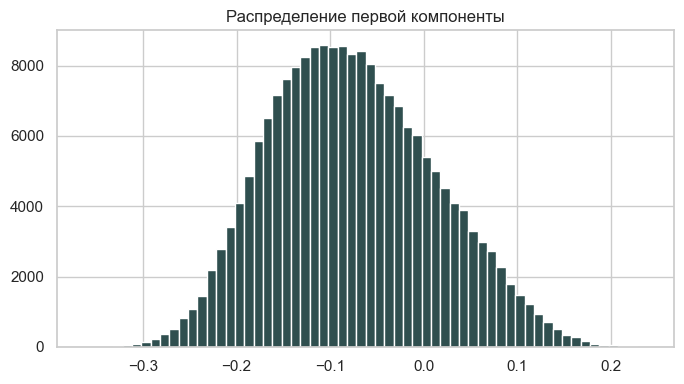

Размерность: 128; нормы: mean=1.000, std=0.0000 (элементы уже L2-нормированы)


In [43]:
pf = pq.ParquetFile(f'{BASE}/embeddings.parquet')
print('Схема:', pf.schema_arrow)
print('Строк в файле:', pf.metadata.num_rows, '; row groups:', pf.metadata.num_row_groups)

batch = next(pf.iter_batches(batch_size=200_000, columns=['item_id', 'normalized_embed']))
emb_df = batch.to_pandas()
E = np.stack(emb_df.normalized_embed.to_numpy()).astype(np.float32)
print('Сэмпл эмбеддингов:', E.shape)

norms = np.linalg.norm(E, axis=1)
plt.figure(figsize=(7, 4))
plt.hist(E[:, 0], bins=60, color='darkslategray')
plt.title('Распределение первой компоненты')
plt.tight_layout(); plt.show()
print(f'Размерность: {E.shape[1]}; нормы: mean={norms.mean():.3f}, std={norms.std():.4f} '
    f'(элементы уже L2-нормированы)')

Покрытие треков 50M этим сэмплом эмбеддингов: 2.420% (сэмпл — первая row-group файла)


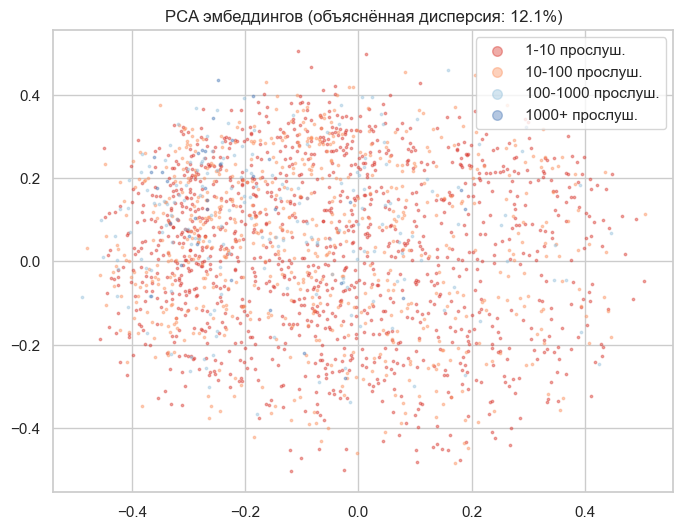

In [44]:
cov = items_50m.isin(emb_df.item_id).mean()
print(f'Покрытие треков 50M этим сэмплом эмбеддингов: {cov:.3%} (сэмпл — первая row-group файла)')

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
idx = np.random.RandomState(42).choice(len(E), size=min(30_000, len(E)), replace=False)
Z = pca.fit_transform(E[idx])
pop = item_agg.reindex(emb_df.item_id.iloc[idx]).n_listens
tier = pd.cut(np.log10(pop.fillna(1)), bins=[0, 1, 2, 3, 6],
              labels=['1-10', '10-100', '100-1000', '1000+'])
plt.figure(figsize=(8, 6))
for t_, c in zip(tier.cat.categories, ['#d73027', '#fc8d59', '#91bfdb', '#4575b4']):
    m = (tier == t_).to_numpy()
    plt.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.4, label=f'{t_} прослуш.', c=c)
plt.legend(markerscale=4); plt.title(f'PCA эмбеддингов (объяснённая дисперсия: {pca.explained_variance_ratio_.sum():.1%})')
plt.show()

Выводы: нормированные эмбеддинги действительно лежат на сфере (нормы ≈ 1), размерность 128. PCA-проекция не показывает сегрегации по популярности — эмбеддинги кодируют звучание, а не популярность, что и нужно от контентного признака: он дополняет коллаборативный сигнал и решает холодный старт треков. Для production-модели эмбеддинги — готовый item-вход для content-based и гибридных моделей.

## 12. Общие выводы и план использования

### Качество данных
Датасет высокого качества пропусков нет (единственные NaN — структурные), невозможных значений нет, размеры сходятся с карточкой. Единственные «аномалии» — дубликаты событий внутри 5-секундного бина (1.3%), `played_ratio > 100` (переслушивания, легитимно) и unlike до like (лайк до окна наблюдений) — все объяснимы и не требуют удаления данных.

### Ключевые свойства для моделирования
1. Экстремальная разреженность плотность матрицы ~0.16%, медианный трек прослушан 3 раза, 28% треков — 1 раз. Понадобятся: фильтрация редчайших айтемов/пользователей при обучении, negative sampling, контентные признаки для хвоста.
2. Сильный перекос популярности топ-1% треков = ~49% прослушиваний, поэтому популярностный бейзлайн будет довольно сильным; качество модели нужно оценивать и по покрытию хвоста (coverage), не только по точности.
3. Двойная природа фидбека implicit (прослушивания, 46.5M) + explicit (лайки 881K, дизлайки 108K). Целевая переменная — `played_ratio > 50%`; лайки/дизлайки используем как взвешивание и отрицательный сигнал.
4. Exposure bias ~48% прослушиваний — из алгоритмических рекомендаций существующей системы, причём они чаще дослушиваются. Учитываем `is_organic` как признак и/или фильтр.
5. Контентные признаки: аудио-эмбеддинги + артисты (покрытие 99.4%) позволяют строить гибридные модели и решать проблему холодного старта.
6. Временная структура 301 день наблюдений, активность растёт (~2x от начала к концу), без обрывов, поэтому берем честный временной сплит (как в официальном бенчмарке датасета) вместо случайного.